# CALPHAD Ni–V Binary Phase Diagrams

This notebook calculates Ni–V phase equilibria from `NiV-19Zou.tdb`. Composition is expressed as **atomic percent (at.%)** and supplied to pycalphad as atomic/mole fraction $X$.

The calculation cells render both composition directions: **Ni–V** (V dissolving) and **V–Ni** (Ni dissolving). The melting calculation uses all thermodynamically relevant phases, because the stable solid next to liquid is composition-dependent.

In [1]:
from collections.abc import Callable, Iterable
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from pycalphad import Database, equilibrium
from pycalphad.mapping import BinaryStrategy, plot_binary
import pycalphad.variables as v

PHASE_AMOUNT_TOLERANCE = 1e-6
TEMPERATURE_TOLERANCE = 0.1
VACANCY_COMPONENT = "VA"

## Database and calculation settings

The focused $10$–$25athrm{at.}$ diagrams report the **all-phase equilibrium** solidus and liquidus. The adjacent solid can be `FCC_A1`, `BCC_A2`, or a multiphase equilibrium, so a fixed solid-plus-liquid phase pair would not reliably represent every selected composition.

In [2]:
DATABASE_DIRECTORY = Path("database")
database_files = sorted(DATABASE_DIRECTORY.glob("*.tdb"))

selected_database = DATABASE_DIRECTORY / "NiV-19Zou.tdb"
binary_elements = ("NI", "V")
pressure = 101325.0  # Pa

# Temperature domains: start, end, step in K.
temperature_range = (300.0, 2600.0, 10.0)
equilibrium_temperature_range = (1450.0, 2100.0, 10.0)

# All relevant phases observed for Ni–V equilibrium in NiV-19Zou.tdb.
all_phases = (
    "LIQUID", "BCC_A2", "FCC_A1", "NI2V", "NI3V_D022",
    "NIV3_A15", "SIGMA_D8B",
)

# Required directions: Ni–V, then V–Ni.
dissolving_elements = ("V", "NI")
focused_boundary_temperature_ranges = {
    "V": (1600.0, 1750.0, 5.0),   # Ni–V: V dissolving
    "NI": (1500.0, 2050.0, 10.0), # V–Ni: Ni dissolving
}
focused_y_axis_ranges = {
    "V": (1600.0, 1730.0),
    "NI": (1500.0, 2050.0),
}
focused_boundary_curve_step_atomic_percent = 0.5
focused_data_point_atomic_percents = {
    "V": (*range(10, 26, 2), 25.0),
    "NI": (*range(10, 26, 2), 25.0),
}
full_atomic_fraction_range = (0.0, 1.0, 0.02)
focused_atomic_fraction_range = (0.10, 0.25, 0.005)

## Thermodynamic calculation and plotting helpers

The helpers validate the selected database, calculate all-phase equilibrium at fixed composition, locate solidus and liquidus transitions by coarse bracketing followed by bisection, and render both composition directions.

In [3]:
def validated_components(database: Database, elements: tuple[str, str]) -> list[str]:
    database_elements = {element.upper() for element in database.elements}
    missing_elements = {element.upper() for element in elements} - database_elements
    if missing_elements:
        raise ValueError(f"Database is missing requested elements: {', '.join(sorted(missing_elements))}.")
    components = [element.upper() for element in elements]
    if VACANCY_COMPONENT in database_elements:
        components.append(VACANCY_COMPONENT)
    return components


def validate_calculation_setup(database: Database, elements: tuple[str, str], phases: tuple[str, ...]) -> list[str]:
    components = validated_components(database, elements)
    missing_phases = {phase.upper() for phase in phases} - {phase.upper() for phase in database.phases}
    if missing_phases:
        raise ValueError(f"Database is missing requested phases: {', '.join(sorted(missing_phases))}.")
    return components


def phase_amounts_at_composition(database: Database, components: list[str], phases: tuple[str, ...], dissolving_element: str, atomic_fraction: float, temperature: float) -> dict[str, float]:
    result = equilibrium(database, components, phases, {
        v.X(dissolving_element): atomic_fraction, v.T: temperature, v.P: pressure, v.N: 1,
    })
    return {
        phase_name.upper(): float(phase_amount)
        for phase_name, phase_amount in zip(result.Phase.values.ravel(), result.NP.values.ravel())
        if phase_name and phase_name != ""
    }


def find_transition_temperature(predicate: Callable[[dict[str, float]], bool], database: Database, components: list[str], phases: tuple[str, ...], dissolving_element: str, atomic_fraction: float, search_temperature_range: tuple[float, float, float]) -> float | None:
    temperature_minimum, temperature_maximum, temperature_step = search_temperature_range
    temperatures = np.arange(temperature_minimum, temperature_maximum + temperature_step, temperature_step)
    previous_temperature = float(temperatures[0])
    previous_result = predicate(phase_amounts_at_composition(database, components, phases, dissolving_element, atomic_fraction, previous_temperature))
    if previous_result:
        return previous_temperature
    for temperature in temperatures[1:]:
        temperature = float(temperature)
        current_result = predicate(phase_amounts_at_composition(database, components, phases, dissolving_element, atomic_fraction, temperature))
        if current_result:
            lower_temperature, upper_temperature = previous_temperature, temperature
            while upper_temperature - lower_temperature > TEMPERATURE_TOLERANCE:
                middle_temperature = (lower_temperature + upper_temperature) / 2
                if predicate(phase_amounts_at_composition(database, components, phases, dissolving_element, atomic_fraction, middle_temperature)):
                    upper_temperature = middle_temperature
                else:
                    lower_temperature = middle_temperature
            return upper_temperature
        previous_temperature, previous_result = temperature, current_result
    return None


def equilibrium_solidus_and_liquidus(database: Database, components: list[str], dissolving_element: str, atomic_fraction: float, search_temperature_range: tuple[float, float, float]) -> tuple[float | None, float | None, str]:
    solidus = find_transition_temperature(lambda amounts: amounts.get("LIQUID", 0.0) > PHASE_AMOUNT_TOLERANCE, database, components, all_phases, dissolving_element, atomic_fraction, search_temperature_range)
    liquidus = find_transition_temperature(lambda amounts: amounts.get("LIQUID", 0.0) >= 1 - PHASE_AMOUNT_TOLERANCE, database, components, all_phases, dissolving_element, atomic_fraction, search_temperature_range)
    if solidus is None:
        return solidus, liquidus, "not found"
    below_solidus = phase_amounts_at_composition(database, components, all_phases, dissolving_element, atomic_fraction, solidus - TEMPERATURE_TOLERANCE)
    solid_phases = sorted(phase for phase, amount in below_solidus.items() if phase != "LIQUID" and amount > PHASE_AMOUNT_TOLERANCE)
    return solidus, liquidus, " + ".join(solid_phases) or "not found"


def system_label(elements: tuple[str, str], dissolving_element: str) -> str:
    solvent = next(element for element in elements if element != dissolving_element)
    return f"{solvent}–{dissolving_element} ({dissolving_element} dissolving)"


def merge_composition_set_legend(axis: Axes) -> None:
    legend = axis.get_legend()
    if legend is None:
        return
    handles, labels = [], []
    for handle, text in zip(legend.legend_handles, legend.get_texts()):
        base_phase = text.get_text().split("#", maxsplit=1)[0]
        if base_phase not in labels:
            handles.append(handle)
            labels.append(base_phase)
    axis.legend(handles=handles, labels=labels, loc="center left", bbox_to_anchor=(1, 0.5))


def plot_diagram_pair(database: Database, components: list[str], phases: tuple[str, ...], composition_range: tuple[float, float, float], diagram_temperature_range: tuple[float, float, float], description: str) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=150)
    for axis, dissolving_element in zip(axes, dissolving_elements):
        strategy = BinaryStrategy(database, components, phases=phases, conditions={
            v.X(dissolving_element): composition_range, v.T: diagram_temperature_range, v.P: pressure, v.N: 1,
        }, plot_kwargs={"ax": axis})
        strategy.do_map()
        plot_binary(strategy, x=v.X(dissolving_element), y=v.T, ax=axis)
        merge_composition_set_legend(axis)
        axis.set_xlim(composition_range[:2])
        axis.set_ylim(diagram_temperature_range[:2])
        axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.set_xlabel(f"Atomic Percent {dissolving_element} (at.%)")
        axis.set_ylabel("Temperature (K)")
        axis.set_title(f"{system_label(binary_elements, dissolving_element)}\n{description}")
        axis.grid(True, which="both", linestyle="--", linewidth=0.5)
    figure.tight_layout()
    plt.show()

In [4]:
def calculate_boundary_data(database: Database, components: list[str], dissolving_element: str, atomic_percents: Iterable[float]) -> pd.DataFrame:
    compositions = np.asarray(tuple(atomic_percents), dtype=float)
    fractions = compositions / 100
    minimum_fraction, maximum_fraction = focused_atomic_fraction_range[:2]
    if np.any(fractions < minimum_fraction) or np.any(fractions > maximum_fraction):
        raise ValueError("All focused atomic-percent values must lie within focused_atomic_fraction_range.")
    records = []
    for atomic_percent, atomic_fraction in zip(compositions, fractions):
        solidus, liquidus, solid_phases = equilibrium_solidus_and_liquidus(database, components, dissolving_element, atomic_fraction, focused_boundary_temperature_ranges[dissolving_element])
        records.append({
            f"{dissolving_element} (at.%)": atomic_percent,
            "Equilibrium solidus (K)": solidus,
            "Equilibrium liquidus (K)": liquidus,
            "Stable solid phase(s) below solidus": solid_phases,
        })
    return pd.DataFrame(records)


def focused_curve_compositions() -> np.ndarray:
    start, end = np.asarray(focused_atomic_fraction_range[:2]) * 100
    step = focused_boundary_curve_step_atomic_percent
    if step <= 0:
        raise ValueError("focused_boundary_curve_step_atomic_percent must be positive.")
    return np.append(np.arange(start, end, step), end)


def plot_focused_diagrams(database: Database, components: list[str]) -> None:
    curve_compositions = focused_curve_compositions()
    for dissolving_element in dissolving_elements:
        curve_data = calculate_boundary_data(database, components, dissolving_element, curve_compositions)
        boundary_data = calculate_boundary_data(database, components, dissolving_element, focused_data_point_atomic_percents[dissolving_element])
        composition_column = f"{dissolving_element} (at.%)"
        solidus_column, liquidus_column = "Equilibrium solidus (K)", "Equilibrium liquidus (K)"
        curve_x = curve_data[composition_column].to_numpy(dtype=float) / 100
        solidus_curve = pd.to_numeric(curve_data[solidus_column], errors="coerce").to_numpy(dtype=float)
        liquidus_curve = pd.to_numeric(curve_data[liquidus_column], errors="coerce").to_numpy(dtype=float)
        valid_curve = np.isfinite(curve_x) & np.isfinite(solidus_curve) & np.isfinite(liquidus_curve)
        if not valid_curve.any():
            raise ValueError(f"No equilibrium melting boundaries found for {dissolving_element}.")
        figure, axis = plt.subplots(figsize=(8, 7), dpi=150)
        axis.plot(curve_x[valid_curve], solidus_curve[valid_curve], color="#00538A", linewidth=1.4)
        axis.plot(curve_x[valid_curve], liquidus_curve[valid_curve], color="#F4C800", linewidth=1.4)
        axis.fill_between(curve_x[valid_curve], solidus_curve[valid_curve], liquidus_curve[valid_curve], color="#F4C800", alpha=0.12)
        point_x = boundary_data[composition_column].to_numpy(dtype=float) / 100
        solidus_points = pd.to_numeric(boundary_data[solidus_column], errors="coerce").to_numpy(dtype=float)
        liquidus_points = pd.to_numeric(boundary_data[liquidus_column], errors="coerce").to_numpy(dtype=float)
        valid_solidus = np.isfinite(point_x) & np.isfinite(solidus_points)
        valid_liquidus = np.isfinite(point_x) & np.isfinite(liquidus_points)
        axis.scatter(point_x[valid_solidus], solidus_points[valid_solidus], color="#00538A", edgecolor="white", linewidth=0.6, s=36, zorder=4)
        axis.scatter(point_x[valid_liquidus], liquidus_points[valid_liquidus], color="#F4C800", edgecolor="white", linewidth=0.6, s=36, zorder=4)
        axis.legend(handles=[Patch(color="#00538A", label="Equilibrium solidus"), Patch(color="#F4C800", label="LIQUID")], loc="upper left", bbox_to_anchor=(1.02, 1))
        axis.set_xlim(focused_atomic_fraction_range[:2])
        axis.set_ylim(focused_y_axis_ranges[dissolving_element])
        axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.set_xlabel(f"Atomic Percent {dissolving_element} (at.%)")
        axis.set_ylabel("Temperature (K)")
        axis.set_title(f"{system_label(binary_elements, dissolving_element)}\nEquilibrium liquidus/solidus region (10–25 at.%)")
        axis.grid(True, which="both", linestyle="--", linewidth=0.5)
        figure.tight_layout()
        plt.show()
        print(f"{system_label(binary_elements, dissolving_element)}: selected equilibrium boundary temperatures")
        display(boundary_data.round(1))

## 1. Full binary system: all phases

This $0$–$100athrm{at.}$ diagram includes `LIQUID`, `BCC_A2`, `FCC_A1`, `NI2V`, `NI3V_D022`, `NIV3_A15`, and `SIGMA_D8B`.

Database: NiV-19Zou.tdb
Components: NI, V, VA
All phases: LIQUID, BCC_A2, FCC_A1, NI2V, NI3V_D022, NIV3_A15, SIGMA_D8B


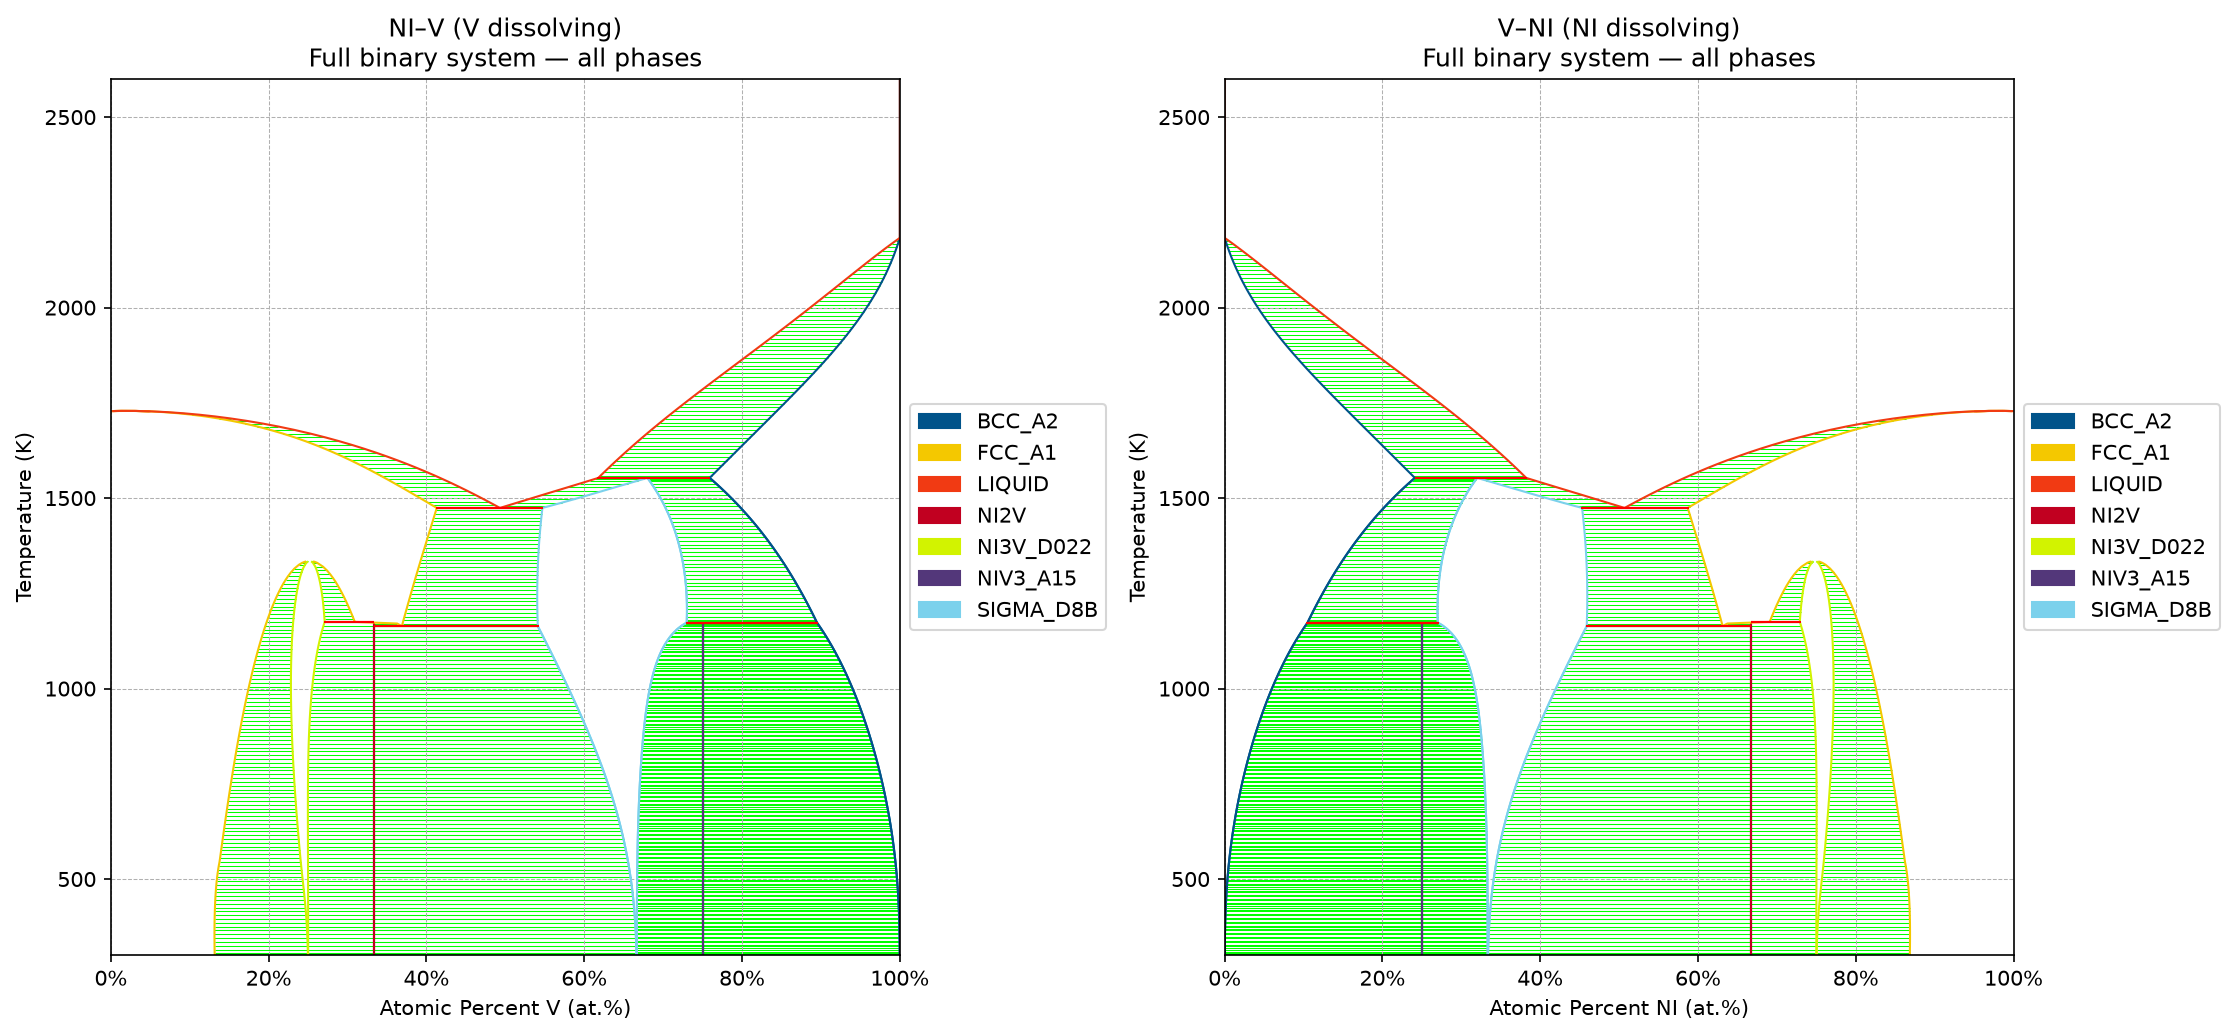

In [5]:
database = Database(selected_database)
calculation_components = validate_calculation_setup(database, binary_elements, all_phases)
print(f"Database: {selected_database.name}")
print(f"Components: {', '.join(calculation_components)}")
print(f"All phases: {', '.join(all_phases)}")
plot_diagram_pair(database, calculation_components, all_phases, full_atomic_fraction_range, temperature_range, "Full binary system — all phases")

## 2. Full binary system: high-temperature equilibrium

This view applies the same all-phase equilibrium model around melting. It avoids a metastable constrained-solid calculation and shows which stable phases contact the liquidus.

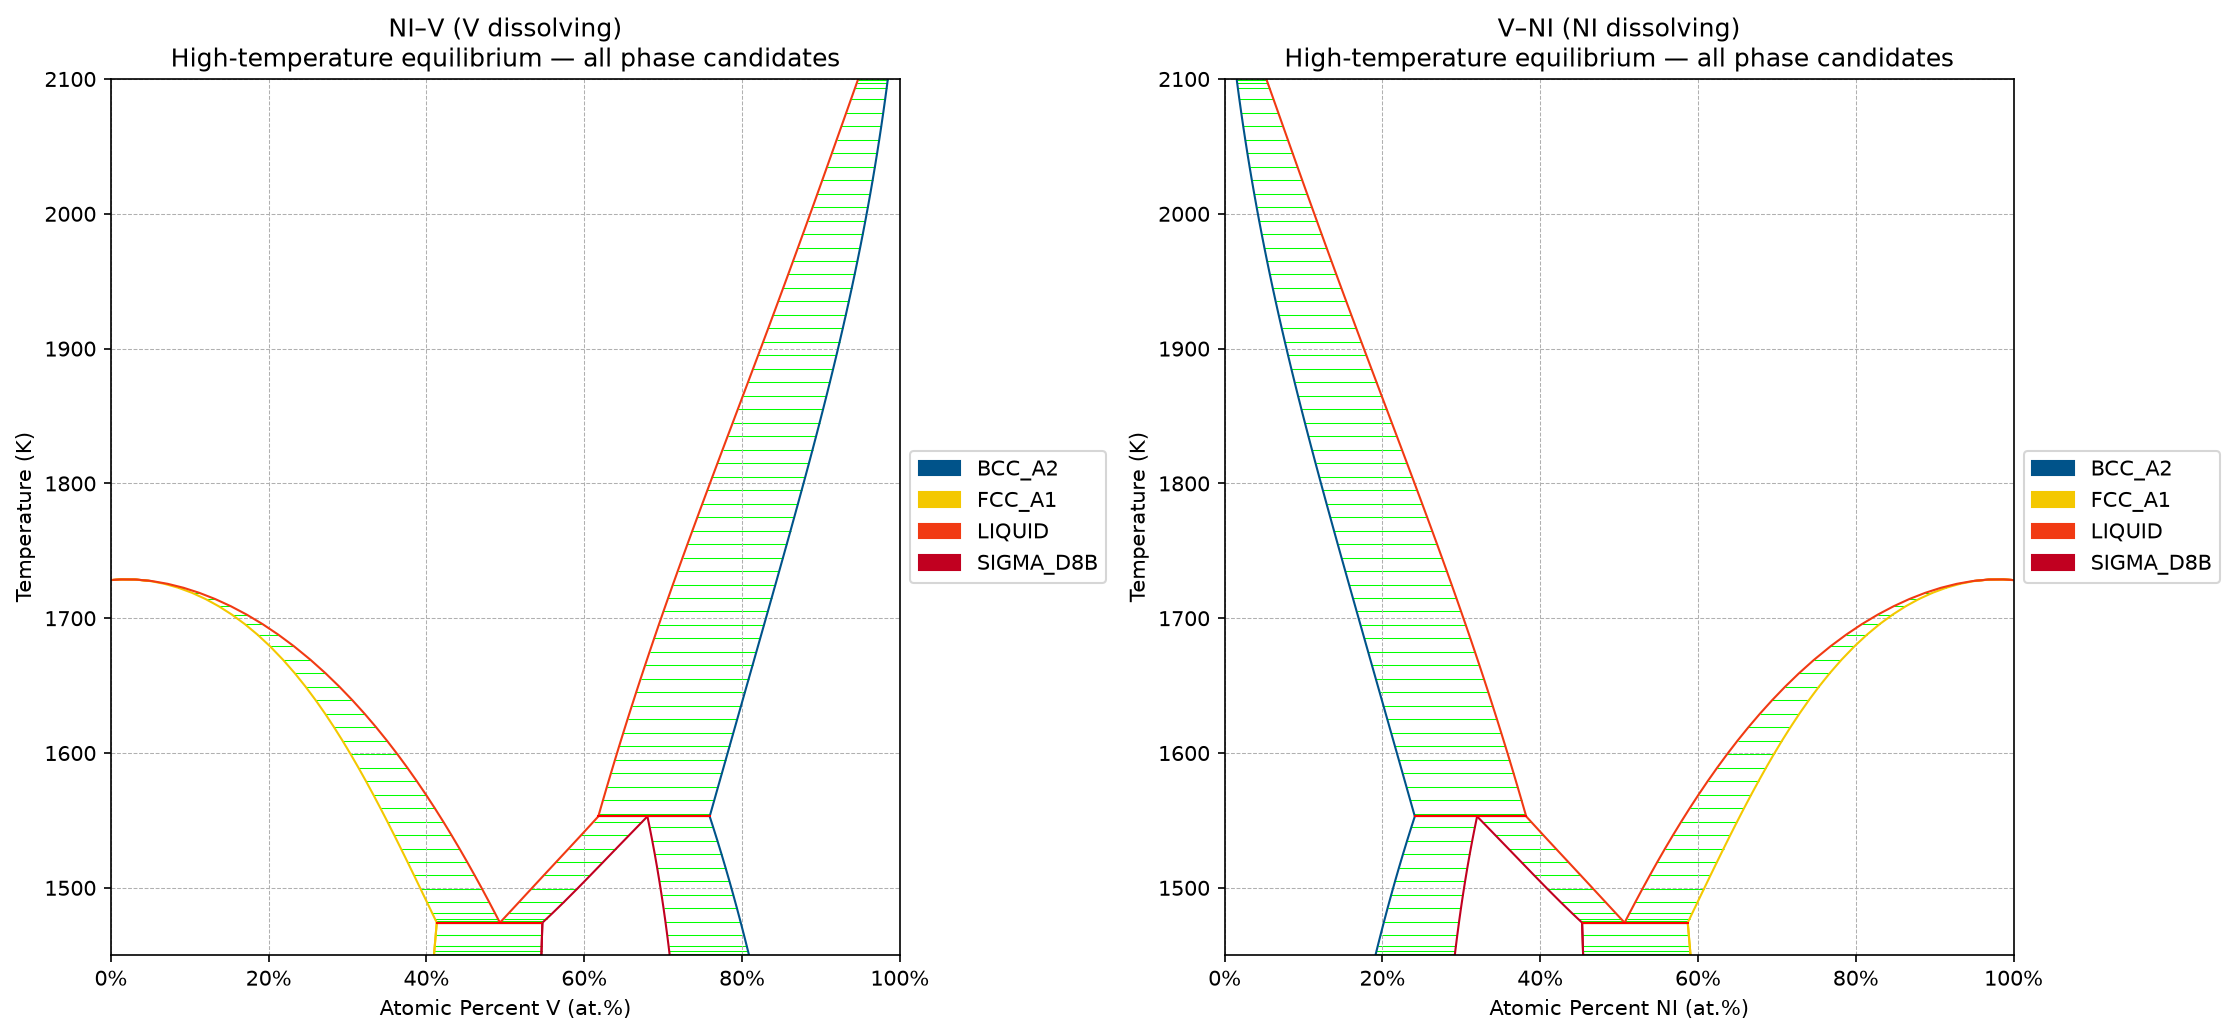

In [6]:
plot_diagram_pair(database, calculation_components, all_phases, full_atomic_fraction_range, equilibrium_temperature_range, "High-temperature equilibrium — all phase candidates")

## 3. Focused system: 10–25 at.% equilibrium liquidus/solidus

Separate figures show Ni–V with V dissolving and V–Ni with Ni dissolving. Markers identify directly calculated equilibrium boundaries, while each table records the phase or phases stable immediately below the solidus.

### Boundary calculation method

At every selected composition, pycalphad minimizes Gibbs energy with all listed phase candidates at $P=101325athrm{Pa}$ and $N=1$. With $arepsilon=10^{-6}$, the boundaries are

$$T_{athrm{s}}=inT:n_{athrm{L}}(T,X)>arepsilon, quad T_{athrm{L}}=inT:n_{athrm{L}}(T,X)e 1-arepsilon.$$

A coarse temperature scan brackets each transition, then bisection refines it to $0.1athrm{K}$. Because the solid can change within the solid-plus-liquid interval, the filled region is the complete equilibrium melting interval rather than a fixed two-phase field.

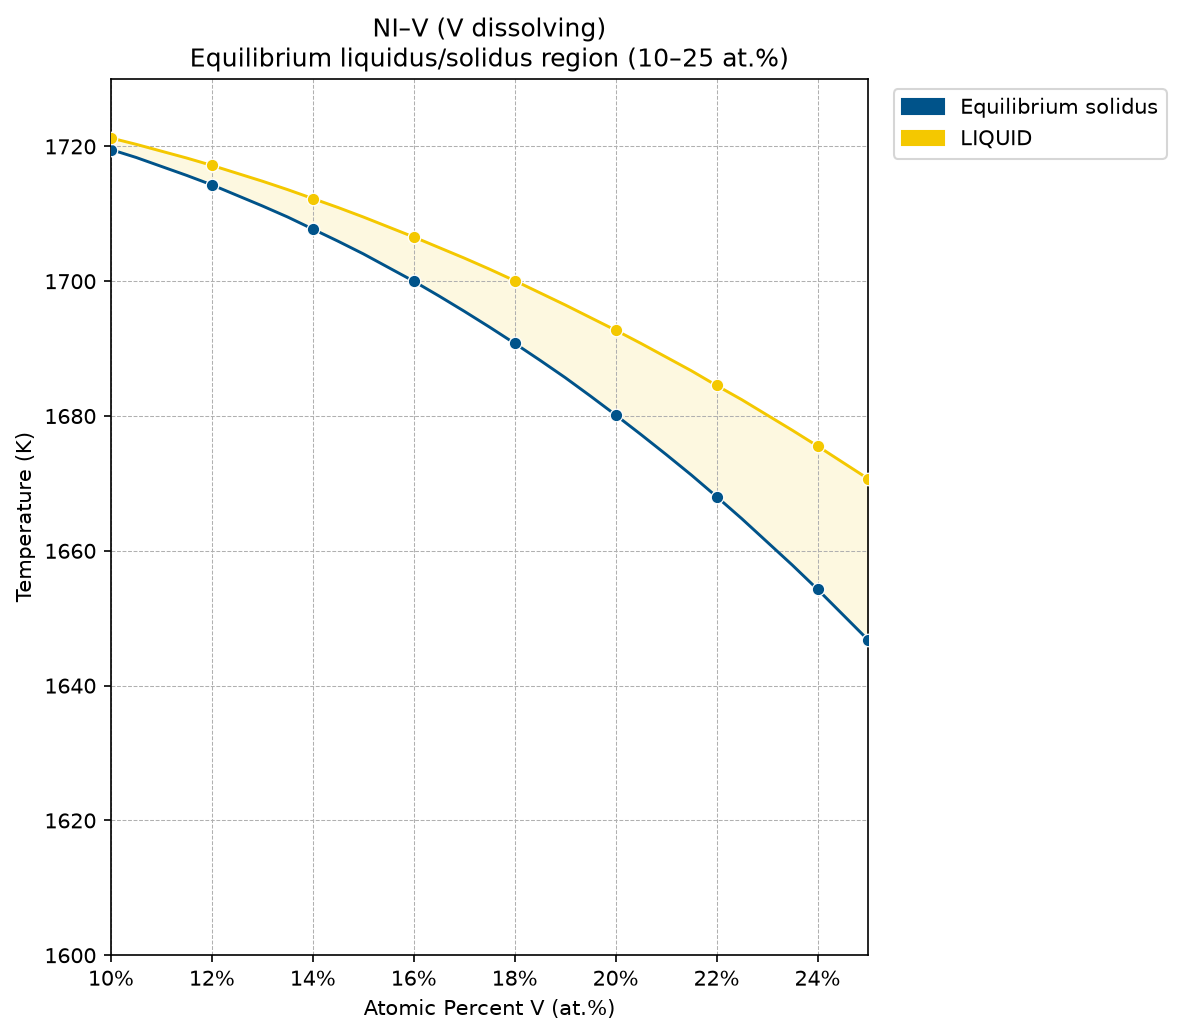

NI–V (V dissolving): selected equilibrium boundary temperatures


,V (at.%),Equilibrium solidus (K),Equilibrium liquidus (K),Stable solid phase(s) below solidus
0,10.0,1719.5,1721.2,FCC_A1
1,12.0,1714.3,1717.2,FCC_A1
2,14.0,1707.7,1712.3,FCC_A1
3,16.0,1700.0,1706.6,FCC_A1
4,18.0,1690.8,1700.1,FCC_A1
5,20.0,1680.2,1692.7,FCC_A1
6,22.0,1668.0,1684.5,FCC_A1
7,24.0,1654.3,1675.5,FCC_A1
8,25.0,1646.8,1670.7,FCC_A1


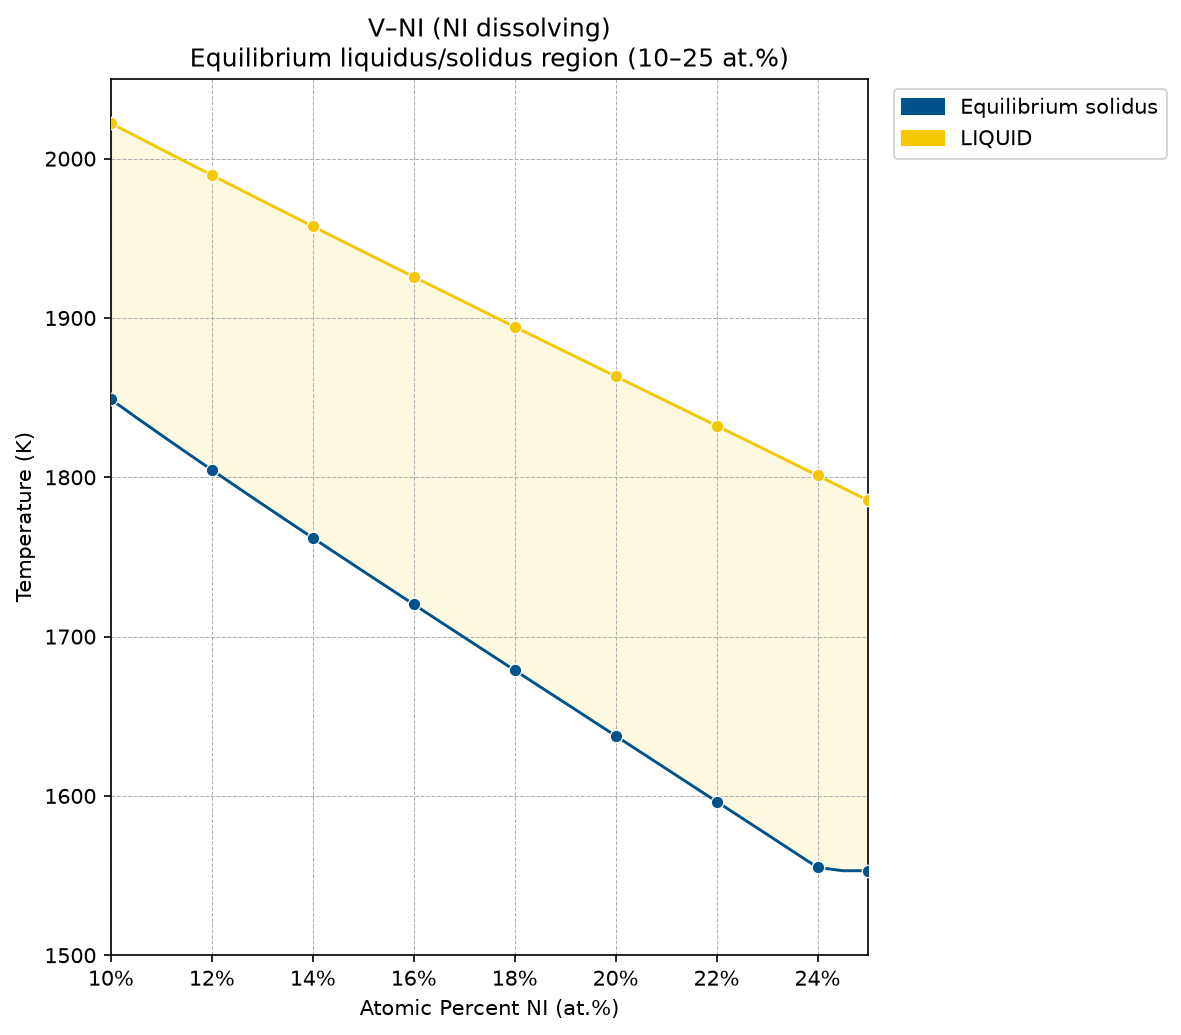

V–NI (NI dissolving): selected equilibrium boundary temperatures


,NI (at.%),Equilibrium solidus (K),Equilibrium liquidus (K),Stable solid phase(s) below solidus
0,10.0,1848.9,2022.2,BCC_A2
1,12.0,1804.6,1989.7,BCC_A2
2,14.0,1762.0,1957.5,BCC_A2
3,16.0,1720.2,1925.9,BCC_A2
4,18.0,1678.9,1894.5,BCC_A2
5,20.0,1637.7,1863.4,BCC_A2
6,22.0,1596.5,1832.3,BCC_A2
7,24.0,1555.2,1801.2,BCC_A2
8,25.0,1553.0,1785.5,BCC_A2 + SIGMA_D8B


In [7]:
plot_focused_diagrams(database, calculation_components)